In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
import h5py
import scipy.sparse as sp
import caiman as cm
from caiman.source_extraction.cnmf.cnmf import load_CNMF

In [20]:
file_key = r"D:\Michael\data.csv"
base_dir =  r"D:\Michael"
info = pd.read_csv(file_key)

In [21]:
def find_cnmfe_paths(info: pd.DataFrame, base_paths: list) -> pd.DataFrame:
    info = info.copy()
    paths = []
    for tseries in info["TSeries_g"]:
        found = None
        for base in base_paths:
            hdf_path = os.path.join(base, tseries, "suite2p", "plane0", "reg_tif", "cnmfe_results.hdf5")
            if os.path.exists(hdf_path):
                found = hdf_path
                break
        paths.append(found)
    info["cnmfe_path"] = paths
    return info

base_paths = [r"D:\Michael",
             r"\\samba.chpc.utah.edu\zelikowsky-group2\Michael\Miniscope_Desktop_Backup"]

info = find_cnmfe_paths(info, base_paths)


In [22]:
info

,Mouse,Session,TSeries_g,cnmfe_path
0,C1F2,R1,dbnst_endo_c1_2024-08-13-12-31-27,\\samba.chpc.utah.edu\zelikowsky-group2\Michae...
1,C1F2,R2,dbnst_endo_c1_2024-08-15-11-58-11,\\samba.chpc.utah.edu\zelikowsky-group2\Michae...
2,C1M1,R1,dbnst_endo_c1_2024-08-13-11-12-56,\\samba.chpc.utah.edu\zelikowsky-group2\Michae...
3,C1M1,R2,dbnst_endo_c1_2024-08-15-10-56-03,\\samba.chpc.utah.edu\zelikowsky-group2\Michae...
4,C1M2,R1,dbnst_endo_c1_2024-08-13-11-39-52,\\samba.chpc.utah.edu\zelikowsky-group2\Michae...
5,C1M2,R2,dbnst_endo_pan_c1_2024-08-15-11-16-50,D:\Michael\dbnst_endo_pan_c1_2024-08-15-11-16-...
6,C2F1,R1,dbnst_endo_c2_2025-07-17-10-36-34,NaN
7,C2F1,R2,dbnst_endo_c2_2025-07-21-10-53-05,D:\Michael\dbnst_endo_c2_2025-07-21-10-53-05\s...
8,C2M4,R1,dbnst_endo_c2_2025-07-17-12-30-13,D:\Michael\dbnst_endo_c2_2025-07-17-12-30-13\s...
9,C2M4,R2,dbnst_endo_c2_2025_07-21-12-34-39,NaN


In [23]:
def find_cnmfe_hdf(mouse, 
                   session, 
                   df, 
                   base_dir):
    """
    Find the cnmfe_results.hdf5 file for a given mouse and session.

    Args:
        mouse: e.g. 'C3M2'
        session: e.g. 'R1'
        df: DataFrame with columns ['Mouse', 'Session', 'TSeries_g']
        base_dir: root directory

    Returns:
        Full path to cnmfe_results.hdf5
    """
    row = df[(df["Mouse"] == mouse) & (df["Session"] == session)]
    if row.empty:
        raise ValueError(f"No entry found for Mouse={mouse}, Session={session}")

    tseries = row.iloc[0]["TSeries_g"]
    hdf_path = os.path.join(base_dir, tseries, "suite2p", "plane0", "reg_tif", "cnmfe_results.hdf5")

    if not os.path.exists(hdf_path):
        raise FileNotFoundError(f"HDF5 file not found: {hdf_path}")

    return hdf_path

In [24]:
cnmf_file = find_cnmfe_hdf('C2M4','R1',info,base_dir)

In [25]:
cnmfe=load_CNMF(cnmf_file)

In [157]:
with h5py.File(cnmf_file, "r") as f:
    estimates =f["estimates"]
    C = f["estimates/C"][:]        # temporal components (neurons x time)
    A_shape =  f["estimates/A/shape"][:]   
    A = f["estimates/A/data"][:]        # spatial components
    dff = f["estimates/F_dff"][:]
    dims = f["estimates/dims"][:]
    A = sp.csc_matrix((f["estimates/A/data"][:],
        f["estimates/A/indices"][:],
        f["estimates/A/indptr"][:]), shape=f["estimates/A/shape"][:])

    A_dense = A.toarray()                          # (n_pixels, n_neurons)
    A_3d = A_dense.reshape(dims[1], dims[0],-1)      # (height, width, n_neurons)


In [27]:
import caiman as cm

# need a caiman estimates object and the movie
cnmf_obj = cm.source_extraction.cnmf.cnmf.load_CNMF(cnmf_file)
estimates = cnmf_obj.estimates

# # also need the memory mapped file
# Yr, dims, T = cm.load_memmap(cnmfe.mmap_file)
# images = np.reshape(Yr, dims + (T,), order='F')
# cnmf_obj.estimates.nb_view_components(img=cnmf_obj.estimates.peak_to_noise_ratio)

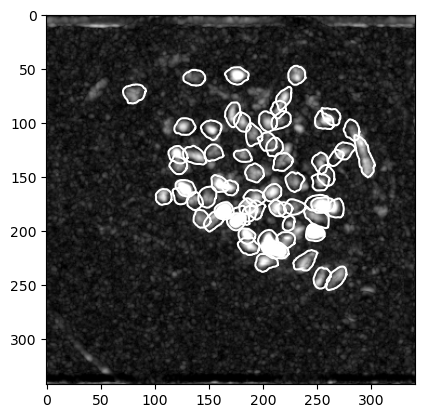

In [30]:
estimates.plot_contours(img = cnmf_obj.estimates.peak_to_noise_ratio,cmap='gray',display_numbers=False)


In [86]:
coords=cm.utils.visualization.get_contours(A,dims)